# 📘 5.4 Neural Network Regression

### Learning nonlinear engineering response surfaces with connected neurons

A multilayer perceptron can combine features through layers of weighted connections and
nonlinear activation functions. This gives neural networks enough flexibility to learn
complicated regression relationships without us specifying their equation.

Flexibility is not the same as reliability. Neural networks are sensitive to scaling,
architecture, optimisation, regularisation, random initialisation and data coverage.
This notebook focuses on making those choices visible and defensible.


### 🎯 Learning Objectives

By the end of this notebook, you should be able to:

* describe inputs, hidden layers, activations and a regression output;
* explain conceptually how forward prediction and iterative training differ;
* build a scaled `MLPRegressor` pipeline;
* investigate architecture, regularisation and random state;
* interpret loss and internal validation curves;
* compare training and external validation performance; and
* recognise limitations involving convergence, interpretability and extrapolation.

### 🔗 Unit Learning Outcome Alignment

This notebook supports **LO1, LO2 and LO3** through method selection, executable
modelling, performance evaluation and engineering limitations.

### 📚 Sources used in this notebook

* scikit-learn — [MLPRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPRegressor.html)
* scikit-learn — [Neural network models user guide](https://scikit-learn.org/stable/modules/neural_networks_supervised.html)
* scikit-learn — [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)
* NREL — [PVWatts Version 5 Manual](https://pvwatts.nrel.gov/downloads/pvwattsv5.pdf)
* Google — [Neural networks: interactive exercises](https://developers.google.com/machine-learning/crash-course/neural-networks/interactive-exercises)
* TensorFlow — [A Neural Network Playground](https://playground.tensorflow.org/)


## 📂 5.4.0 How to use this notebook

Run every code cell from top to bottom. No cell requires editing or typed input. The
Week 5 workbook will turn the model choices into guided exploration and problem-solving
tasks.


## 📂 5.4.1 What is a regression neural network?

A network receives numerical **input features**, transforms them through one or more
**hidden layers**, and produces a continuous **output**. A neuron first calculates

$$z=w_1x_1+w_2x_2+\cdots+w_mx_m+b,$$

then applies an activation function $g$ to obtain $h=g(z)$. The weights $w_j$ and bias
$b$ are parameters learned from data.

Without nonlinear activations, stacking layers still reduces to a linear mapping.
Activations allow the network to construct curved and interacting relationships.


In [ ]:
from IPython.display import HTML, display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.precision", 4)

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def metrics(y_true, y_pred):
    return {
        "MAE_kW": mean_absolute_error(y_true, y_pred),
        "RMSE_kW": rmse(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }


### Common hidden-layer activations

`MLPRegressor` can use identity, logistic, hyperbolic-tangent or rectified-linear-unit
activations in hidden layers. ReLU is zero for negative inputs and linear for positive
inputs. `tanh` is smooth and bounded between −1 and 1.

The regression output uses an identity activation by default, so predictions are not
automatically restricted to a physical range.


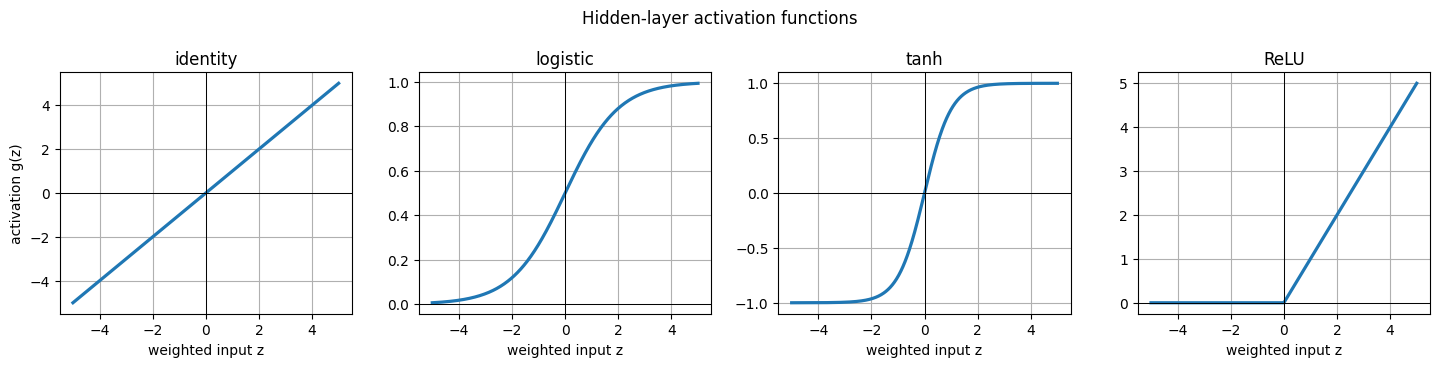

In [ ]:
z = np.linspace(-5, 5, 500)
activations = {
    "identity": z,
    "logistic": 1 / (1 + np.exp(-z)),
    "tanh": np.tanh(z),
    "ReLU": np.maximum(0, z),
}

fig, axes = plt.subplots(1, 4, figsize=(14.5, 3.7), sharex=True)
for ax, (name, values) in zip(axes, activations.items()):
    ax.plot(z, values, linewidth=2.3)
    ax.axhline(0, color="black", linewidth=0.7)
    ax.axvline(0, color="black", linewidth=0.7)
    ax.set_title(name); ax.set_xlabel("weighted input z"); ax.grid(True)
axes[0].set_ylabel("activation g(z)")
fig.suptitle("Hidden-layer activation functions")
fig.tight_layout(); plt.show()


## 📂 5.4.2 Reading a network architecture

`hidden_layer_sizes=(5,)` means one hidden layer with five neurons. `(8, 4)` means two
hidden layers containing eight and four neurons. Every connection has a learned weight,
and each non-input neuron has a learned bias.

More neurons and layers increase capacity and parameter count. They do not guarantee
better validation performance.


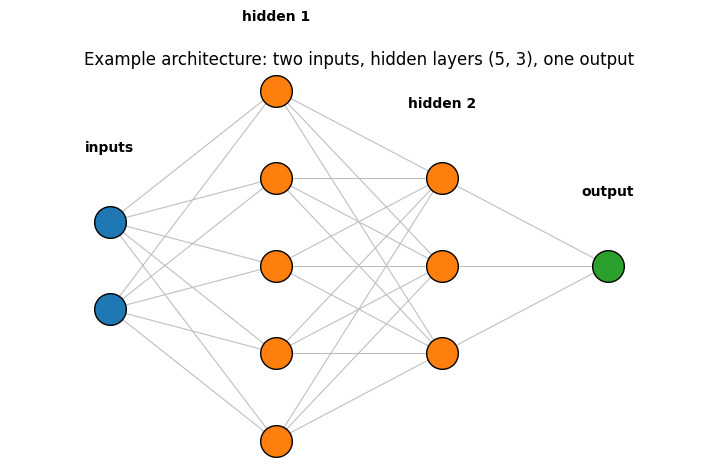

In [ ]:
def draw_network(layer_sizes, layer_labels):
    fig, ax = plt.subplots(figsize=(9, 5))
    x_positions = np.arange(len(layer_sizes))
    positions = []
    for x, size in zip(x_positions, layer_sizes):
        y_positions = np.linspace(-(size - 1) / 2, (size - 1) / 2, size)
        positions.append([(x, y) for y in y_positions])
    for left, right in zip(positions[:-1], positions[1:]):
        for x1, y1 in left:
            for x2, y2 in right:
                ax.plot([x1, x2], [y1, y2], color="0.75", linewidth=0.8, zorder=1)
    colours = ["tab:blue", "tab:orange", "tab:orange", "tab:green"]
    for layer, colour, label in zip(positions, colours, layer_labels):
        xs, ys = zip(*layer)
        ax.scatter(xs, ys, s=520, color=colour, edgecolor="black", zorder=2)
        ax.text(layer[0][0], max(ys) + 0.8, label, ha="center", fontweight="bold")
    ax.set_xlim(-0.6, len(layer_sizes) - 0.4); ax.axis("off")
    ax.set_title("Example architecture: two inputs, hidden layers (5, 3), one output")
    plt.show()

draw_network([2, 5, 3, 1], ["inputs", "hidden 1", "hidden 2", "output"])


## 📂 5.4.3 How does the network learn?

**Forward prediction** passes features through the current weights to calculate
$\hat y$. Training then compares predictions with targets using a loss. For squared-error
regression, scikit-learn minimises a half-squared-error term plus L2 regularisation:

$$J(W)=\frac{1}{2n}\sum_{i=1}^{n}(y_i-\hat y_i)^2
+\frac{\alpha}{2n}\lVert W\rVert_2^2.$$

**Backpropagation** calculates how the loss changes with each parameter. An optimiser
repeatedly updates the parameters to reduce the loss. Training is iterative and the
resulting loss surface is non-convex, so different initial weights can lead to different
fitted models.


## 📂 5.4.4 Engineering example: photovoltaic system output

The NREL PVWatts model relates photovoltaic DC power to plane-of-array irradiance and
cell temperature. Irradiance generally increases output, while elevated cell temperature
reduces efficiency.

### ⚠️ Data provenance

The dataset below is **synthetic and deterministic**. Its main irradiance–temperature
relationship follows the form documented by PVWatts. We add a teaching-only low-light
efficiency effect, inverter saturation and measurement noise so the response is
nonlinear. It is not a certified system model and must not be used for design or yield
prediction. The noise-free function is retained only for teaching evaluation.


In [ ]:
rng = np.random.default_rng(5401)
n_samples = 360
irradiance_wm2 = rng.uniform(80.0, 1100.0, n_samples)
cell_temperature_c = rng.uniform(5.0, 75.0, n_samples)

rated_dc_kw = 6.0
temperature_coefficient_per_c = -0.0035
ideal_dc_kw = (irradiance_wm2 / 1000.0) * rated_dc_kw * (
    1 + temperature_coefficient_per_c * (cell_temperature_c - 25.0)
)
low_light_factor = 1 - 0.08 * np.exp(-irradiance_wm2 / 180.0)
noise_free_ac_kw = np.clip(0.96 * ideal_dc_kw * low_light_factor, 0.0, 5.2)
measured_ac_kw = np.clip(noise_free_ac_kw + rng.normal(0.0, 0.10, n_samples), 0.0, None)

pv_data = pd.DataFrame({
    "irradiance_wm2": irradiance_wm2,
    "cell_temperature_c": cell_temperature_c,
    "measured_ac_power_kw": measured_ac_kw,
    "true_power_for_teaching_only_kw": noise_free_ac_kw,
})
pv_data.head(8)


,irradiance_wm2,cell_temperature_c,measured_ac_power_kw,true_power_for_teaching_only_kw
0,279.1402,15.0390,1.6454,1.6357
1,218.3820,59.8522,1.0465,1.0782
2,352.6485,6.5388,2.1702,2.1381
3,986.0240,73.1208,4.8552,4.7214
4,672.1867,59.2610,3.3446,3.4010
5,1031.9393,43.0400,5.3348,5.2000
6,143.0777,45.2809,0.6522,0.7380
7,741.6236,28.6183,4.2609,4.2122


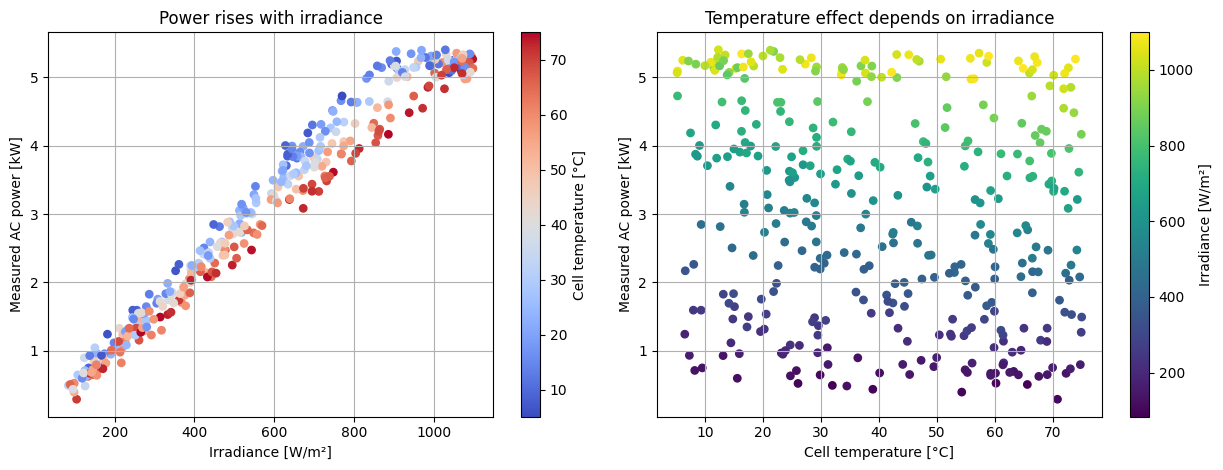

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
first = axes[0].scatter(pv_data.irradiance_wm2, pv_data.measured_ac_power_kw,
                        c=pv_data.cell_temperature_c, cmap="coolwarm", s=28)
axes[0].set(xlabel="Irradiance [W/m²]", ylabel="Measured AC power [kW]",
            title="Power rises with irradiance")
fig.colorbar(first, ax=axes[0], label="Cell temperature [°C]")
second = axes[1].scatter(pv_data.cell_temperature_c, pv_data.measured_ac_power_kw,
                         c=pv_data.irradiance_wm2, cmap="viridis", s=28)
axes[1].set(xlabel="Cell temperature [°C]", ylabel="Measured AC power [kW]",
            title="Temperature effect depends on irradiance")
fig.colorbar(second, ax=axes[1], label="Irradiance [W/m²]")
for ax in axes: ax.grid(True)
fig.tight_layout(); plt.show()


### 🧠 What should you notice?

A two-dimensional relationship cannot be judged completely from either scatter plot.
At high irradiance, inverter saturation creates a plateau. Temperature has a stronger
absolute effect when more solar power is available. This is an interaction between
features.


## 📂 5.4.5 External training and validation data

We keep 25% of the observations away from fitting for external validation. Later,
`early_stopping=True` will reserve an additional internal fraction from the training
subset. The external validation set remains separate from that optimisation process.


In [ ]:
X = pv_data[["irradiance_wm2", "cell_temperature_c"]]
y = pv_data["measured_ac_power_kw"]
X_train, X_validation, y_train, y_validation = train_test_split(
    X, y, test_size=0.25, random_state=42
)
pd.DataFrame({"subset": ["training", "external validation"],
              "samples": [len(X_train), len(X_validation)]})


,subset,samples
0,training,270
1,external validation,90


## 📂 5.4.6 Why scaling matters

Irradiance is measured in hundreds of W/m², while temperature is measured in tens of
degrees. Neural-network optimisation is sensitive to these numerical scales. A
`StandardScaler` inside the pipeline learns the training mean and standard deviation for
each feature and applies the same transformation during prediction.


In [ ]:
def make_mlp(random_state=42, hidden_layer_sizes=(20,), alpha=0.001,
             early_stopping=True):
    return MLPRegressor(
        hidden_layer_sizes=hidden_layer_sizes,
        activation="relu",
        solver="adam",
        alpha=alpha,
        learning_rate_init=0.01,
        max_iter=2500,
        early_stopping=early_stopping,
        validation_fraction=0.15,
        n_iter_no_change=35,
        tol=1e-5,
        random_state=random_state,
    )

scaling_models = {
    "Unscaled MLP": make_mlp(),
    "Scaled MLP pipeline": make_pipeline(StandardScaler(), make_mlp()),
}
scaling_rows = []
for label, model in scaling_models.items():
    model.fit(X_train, y_train)
    scaling_rows.append({"model": label,
                         **metrics(y_validation, model.predict(X_validation))})
scaling_results = pd.DataFrame(scaling_rows).set_index("model")
scaling_results


,MAE_kW,RMSE_kW,R2
model,,,
Unscaled MLP,0.1754,0.2251,0.9745
Scaled MLP pipeline,0.1245,0.1603,0.9871


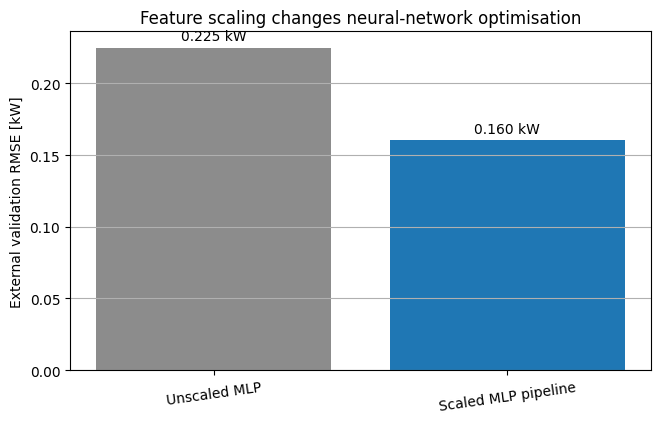

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 4.4))
bars = ax.bar(scaling_results.index, scaling_results.RMSE_kW, color=["0.55", "tab:blue"])
ax.bar_label(bars, fmt="%.3f kW", padding=3)
ax.set(ylabel="External validation RMSE [kW]",
       title="Feature scaling changes neural-network optimisation")
ax.grid(True, axis="y"); plt.xticks(rotation=8); plt.show()


### ⚠️ Point of note

Scaling does not add information and does not guarantee a good network. It makes the
optimisation problem better conditioned and prevents feature units from controlling
update magnitudes. Fit the scaler on training data only.


## 📂 5.4.7 Compare with a linear baseline

A flexible model should earn its complexity. We compare the scaled MLP with ordinary
linear regression using the same training and external validation observations.


In [ ]:
baseline = LinearRegression().fit(X_train, y_train)
selected_mlp = make_pipeline(StandardScaler(), make_mlp())
selected_mlp.fit(X_train, y_train)

comparison = pd.DataFrame([
    {"model": "Linear regression", **metrics(y_validation, baseline.predict(X_validation))},
    {"model": "Scaled MLP", **metrics(y_validation, selected_mlp.predict(X_validation))},
]).set_index("model")
comparison


,MAE_kW,RMSE_kW,R2
model,,,
Linear regression,0.1527,0.2007,0.9797
Scaled MLP,0.1245,0.1603,0.9871


## 📂 5.4.8 Visualising the learned response surface

A response surface reveals behaviour that one overall score cannot. We compare the
synthetic teaching relationship, neural prediction and absolute difference across the
sampled feature rectangle.


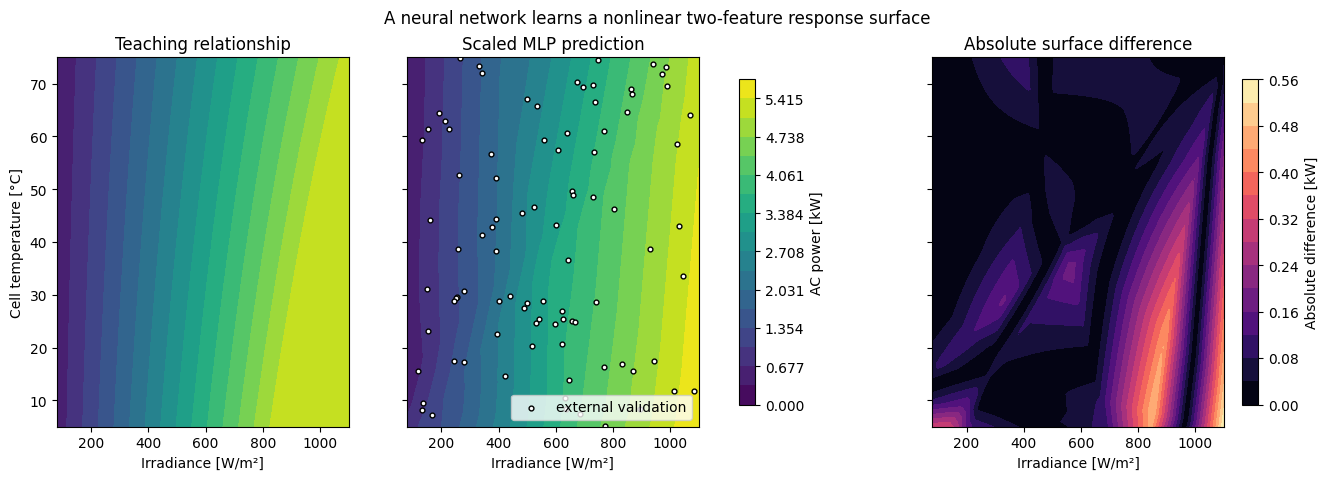

In [ ]:
irradiance_axis = np.linspace(80.0, 1100.0, 150)
temperature_axis = np.linspace(5.0, 75.0, 150)
irradiance_surface, temperature_surface = np.meshgrid(irradiance_axis, temperature_axis)
surface_queries = pd.DataFrame({
    "irradiance_wm2": irradiance_surface.ravel(),
    "cell_temperature_c": temperature_surface.ravel(),
})
ideal_surface = (irradiance_surface / 1000) * rated_dc_kw * (
    1 + temperature_coefficient_per_c * (temperature_surface - 25)
)
truth_surface = np.clip(
    0.96 * ideal_surface * (1 - 0.08 * np.exp(-irradiance_surface / 180)), 0, 5.2
)
predicted_surface = selected_mlp.predict(surface_queries).reshape(irradiance_surface.shape)
error_surface = np.abs(predicted_surface - truth_surface)
power_levels = np.linspace(0, max(truth_surface.max(), predicted_surface.max()), 18)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharex=True, sharey=True)
axes[0].contourf(irradiance_surface, temperature_surface, truth_surface,
                 levels=power_levels, cmap="viridis")
power_map = axes[1].contourf(irradiance_surface, temperature_surface, predicted_surface,
                            levels=power_levels, cmap="viridis")
error_map = axes[2].contourf(irradiance_surface, temperature_surface, error_surface,
                            levels=15, cmap="magma")
axes[0].set_title("Teaching relationship"); axes[1].set_title("Scaled MLP prediction")
axes[2].set_title("Absolute surface difference")
axes[1].scatter(X_validation.irradiance_wm2, X_validation.cell_temperature_c,
                c="white", edgecolor="black", s=12, label="external validation")
axes[1].legend(loc="lower right")
for ax in axes: ax.set_xlabel("Irradiance [W/m²]")
axes[0].set_ylabel("Cell temperature [°C]")
fig.colorbar(power_map, ax=axes[:2], shrink=0.88, label="AC power [kW]")
fig.colorbar(error_map, ax=axes[2], shrink=0.88, label="Absolute difference [kW]")
fig.suptitle("A neural network learns a nonlinear two-feature response surface")
plt.show()


### 🧠 What should you notice?

The network represents the interaction and saturation without receiving their equations.
The approximation is not uniformly accurate. The exact difference surface is available
only because the data are synthetic; real work requires validation measurements and
engineering checks.


## 📂 5.4.9 Architecture and parameter count

Architecture is a modelling choice. We compare a very small network, a moderate network
and a deeper network. Training RMSE and external validation RMSE reveal whether added
capacity produces useful generalisation.


In [ ]:
def parameter_count(fitted_mlp):
    return sum(w.size for w in fitted_mlp.coefs_) + sum(b.size for b in fitted_mlp.intercepts_)

architectures = {"Small (3,)": (3,), "Moderate (20,)": (20,), "Deep (30, 15)": (30, 15)}
architecture_rows = []
architecture_models = {}
for label, architecture in architectures.items():
    model = make_pipeline(StandardScaler(),
        make_mlp(hidden_layer_sizes=architecture, random_state=42))
    model.fit(X_train, y_train)
    fitted = model.named_steps["mlpregressor"]
    architecture_models[label] = model
    architecture_rows.append({
        "architecture": label,
        "parameters": parameter_count(fitted),
        "iterations": fitted.n_iter_,
        "training_RMSE_kW": rmse(y_train, model.predict(X_train)),
        "validation_RMSE_kW": rmse(y_validation, model.predict(X_validation)),
    })
architecture_results = pd.DataFrame(architecture_rows).set_index("architecture")
architecture_results


,parameters,iterations,training_RMSE_kW,validation_RMSE_kW
architecture,,,,
"Small (3,)",13,587,0.2237,0.2070
"Moderate (20,)",81,167,0.1630,0.1603
"Deep (30, 15)",571,637,0.1010,0.1252


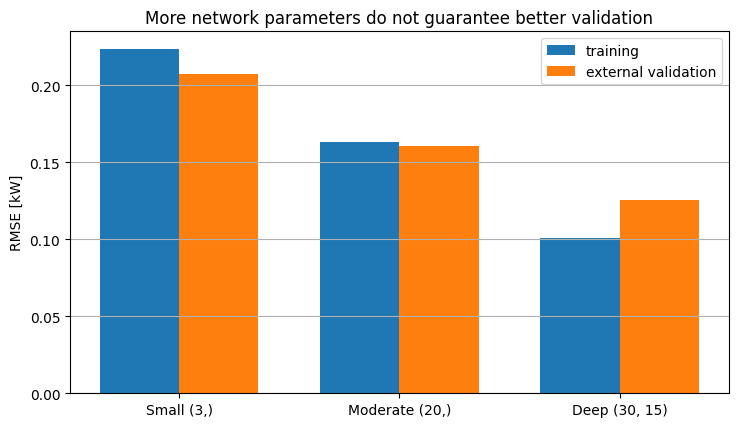

In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 4.7))
x = np.arange(len(architecture_results)); width = 0.36
ax.bar(x - width/2, architecture_results.training_RMSE_kW, width, label="training")
ax.bar(x + width/2, architecture_results.validation_RMSE_kW, width,
       label="external validation")
ax.set_xticks(x, architecture_results.index)
ax.set(ylabel="RMSE [kW]", title="More network parameters do not guarantee better validation")
ax.grid(True, axis="y"); ax.legend(); plt.show()


### 🧩 Inspecting fitted weights

`coefs_` stores one weight matrix for each pair of adjacent layers. For two input
features, a `(20,)` hidden layer and one output, the matrices have shapes `(2, 20)` and
`(20, 1)`. Individual weights are rarely meaningful in isolation because neurons act
together and can be represented in several equivalent ways.


In [ ]:
fitted_selected = selected_mlp.named_steps["mlpregressor"]
pd.DataFrame({
    "connection": ["input → hidden", "hidden → output"],
    "weight_matrix_shape": [str(w.shape) for w in fitted_selected.coefs_],
    "bias_vector_shape": [str(b.shape) for b in fitted_selected.intercepts_],
})


,connection,weight_matrix_shape,bias_vector_shape
0,input → hidden,"(2, 20)","(20,)"
1,hidden → output,"(20, 1)","(1,)"


## 📂 5.4.10 Convergence and early stopping

With the Adam solver, one iteration is one epoch through the training samples. The loss
curve records the training objective after each epoch. With `early_stopping=True`,
scikit-learn also reserves part of the training subset and records its R² score.

Training stops when the internal validation score fails to improve sufficiently for
`n_iter_no_change` epochs. This internal set helps control optimisation; it does not
replace our untouched external validation set.


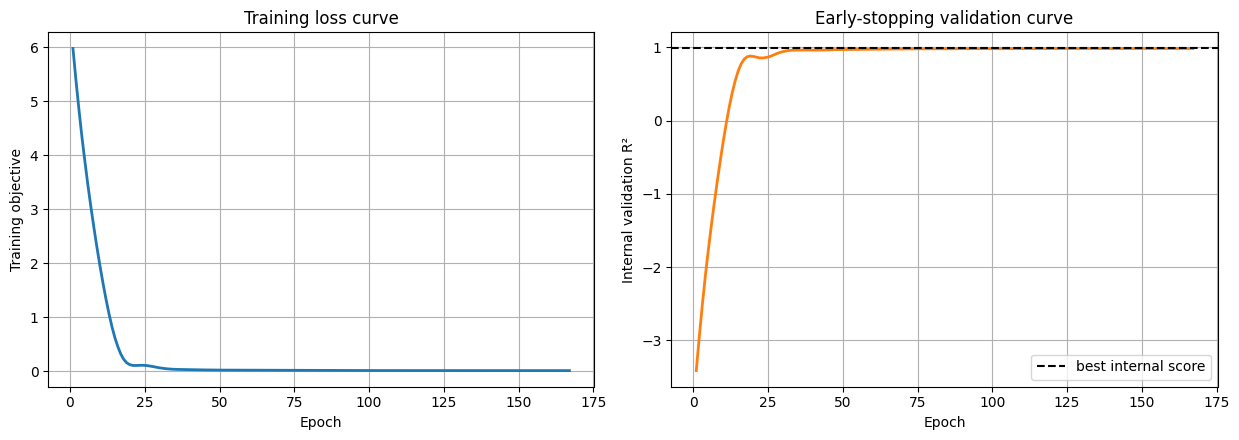

In [ ]:
epochs = np.arange(1, fitted_selected.n_iter_ + 1)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))
axes[0].plot(epochs, fitted_selected.loss_curve_, linewidth=2)
axes[0].set(xlabel="Epoch", ylabel="Training objective",
            title="Training loss curve")
axes[1].plot(epochs, fitted_selected.validation_scores_, linewidth=2,
             color="tab:orange")
axes[1].axhline(fitted_selected.best_validation_score_, linestyle="--",
                color="black", label="best internal score")
axes[1].set(xlabel="Epoch", ylabel="Internal validation R²",
            title="Early-stopping validation curve")
for ax in axes: ax.grid(True)
axes[1].legend(); fig.tight_layout(); plt.show()


### 🎞️ Watch the model learn

A loss curve summarises training, but it does not show what is happening to the fitted
function. The next cells train a fresh scaled `(20,)` MLP one epoch at a time and create
two animations entirely from Python. They do not download or read an external media or
data file.

The first animation follows the prediction at 25 °C together with training and external-
validation RMSE. The second follows the complete two-feature response surface. Use the
animation controls to pause, replay or move between the 19 saved checkpoints.

### 🌐 Optional online visual explainers

* [Google's neural-network interactive exercises](https://developers.google.com/machine-learning/crash-course/neural-networks/interactive-exercises)
  animate forward calculation and model training while allowing architecture, activation
  and learning-rate changes.
* [TensorFlow Playground](https://playground.tensorflow.org/) lets you watch weights,
  hidden representations and a decision surface change during training. It demonstrates
  classification, but the ideas of layers, activations and optimisation transfer to
  regression.
* [Gradient descent: how neural networks learn](https://www.youtube.com/watch?v=IHZwWFHWa-w)
  by 3Blue1Brown gives a visual explanation of loss minimisation and parameter updates.
* [scikit-learn's MLP training-curve example](https://scikit-learn.org/stable/auto_examples/neural_networks/plot_mlp_training_curves.html)
  compares Adam and stochastic-gradient learning strategies using executable code.


In [ ]:
from matplotlib.animation import FuncAnimation

animation_scaler = StandardScaler().fit(X_train)
animation_X_train = animation_scaler.transform(X_train)
animation_X_validation = animation_scaler.transform(X_validation)

animation_irradiance = np.linspace(80.0, 1100.0, 180)
animation_slice = pd.DataFrame({
    "irradiance_wm2": animation_irradiance,
    "cell_temperature_c": 25.0,
})
animation_slice_scaled = animation_scaler.transform(animation_slice)

animation_irradiance_axis = np.linspace(80.0, 1100.0, 70)
animation_temperature_axis = np.linspace(5.0, 75.0, 55)
animation_irradiance_mesh, animation_temperature_mesh = np.meshgrid(
    animation_irradiance_axis,
    animation_temperature_axis,
)
animation_surface_queries = pd.DataFrame({
    "irradiance_wm2": animation_irradiance_mesh.ravel(),
    "cell_temperature_c": animation_temperature_mesh.ravel(),
})
animation_surface_scaled = animation_scaler.transform(animation_surface_queries)

animation_model = MLPRegressor(
    hidden_layer_sizes=(20,),
    activation="relu",
    solver="adam",
    alpha=0.001,
    learning_rate_init=0.01,
    max_iter=1,
    random_state=42,
)
capture_epochs = {
    1, 2, 3, 5, 8, 12, 16, 22, 30, 40,
    52, 66, 82, 100, 120, 140, 160, 180, 200,
}
animation_training_rmse = []
animation_validation_rmse = []
animation_snapshots = []

for epoch in range(1, 201):
    animation_model.partial_fit(animation_X_train, y_train)
    animation_training_rmse.append(
        rmse(y_train, animation_model.predict(animation_X_train))
    )
    animation_validation_rmse.append(
        rmse(y_validation, animation_model.predict(animation_X_validation))
    )
    if epoch in capture_epochs:
        animation_snapshots.append({
            "epoch": epoch,
            "slice_prediction": animation_model.predict(animation_slice_scaled),
            "surface_prediction": animation_model.predict(
                animation_surface_scaled
            ).reshape(animation_irradiance_mesh.shape),
            "training_rmse": np.array(animation_training_rmse),
            "validation_rmse": np.array(animation_validation_rmse),
        })

animation_truth_slice = np.clip(
    0.96 * (animation_irradiance / 1000.0) * rated_dc_kw
    * (1 - 0.08 * np.exp(-animation_irradiance / 180.0)),
    0.0,
    5.2,
)
near_25_c = np.abs(X_train["cell_temperature_c"] - 25.0) <= 4.0

curve_figure, curve_axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
curve_axes[0].scatter(
    X_train.loc[near_25_c, "irradiance_wm2"],
    y_train.loc[near_25_c],
    s=22,
    alpha=0.55,
    color="0.45",
    label="training samples near 25 °C",
)
curve_axes[0].plot(
    animation_irradiance,
    animation_truth_slice,
    "--",
    linewidth=2,
    label="teaching relationship at 25 °C",
)
current_prediction_line, = curve_axes[0].plot(
    [], [], linewidth=2.5, label="current MLP prediction"
)
curve_axes[0].set(
    xlim=(80, 1100), ylim=(-0.4, 5.8),
    xlabel="Irradiance [W/m²]", ylabel="AC power [kW]",
)
curve_axes[0].grid(True)
curve_axes[0].legend(loc="lower right", fontsize=8)

training_error_line, = curve_axes[1].plot([], [], label="training RMSE")
validation_error_line, = curve_axes[1].plot([], [], label="external validation RMSE")
current_error_point, = curve_axes[1].plot([], [], "o")
curve_axes[1].set(
    xlim=(1, 200), ylim=(0, 3.2),
    xlabel="Epoch", ylabel="RMSE [kW]",
)
curve_axes[1].grid(True)
curve_axes[1].legend()
curve_figure.suptitle("A neural network changes as its weights are updated")
curve_figure.tight_layout()

def update_curve_animation(frame_index):
    snapshot = animation_snapshots[frame_index]
    epochs_so_far = np.arange(1, snapshot["epoch"] + 1)
    current_prediction_line.set_data(
        animation_irradiance,
        snapshot["slice_prediction"],
    )
    training_error_line.set_data(epochs_so_far, snapshot["training_rmse"])
    validation_error_line.set_data(epochs_so_far, snapshot["validation_rmse"])
    current_error_point.set_data(
        [snapshot["epoch"]],
        [snapshot["validation_rmse"][-1]],
    )
    curve_axes[0].set_title(f"Prediction after epoch {snapshot['epoch']}")
    curve_axes[1].set_title(
        f"Validation RMSE = {snapshot['validation_rmse'][-1]:.3f} kW"
    )
    return (
        current_prediction_line,
        training_error_line,
        validation_error_line,
        current_error_point,
    )

curve_animation = FuncAnimation(
    curve_figure,
    update_curve_animation,
    frames=len(animation_snapshots),
    interval=300,
    repeat=True,
)
plt.close(curve_figure)
HTML(curve_animation.to_jshtml(default_mode="loop"))


Early in training, the randomly initialised network gives a poor response. Repeated
updates rapidly recover the overall irradiance trend, then make smaller changes.
Validation error need not fall every time training error falls.

The next cell uses the stored checkpoints to animate the complete two-feature surface.
The colour scale stays fixed so that changes are directly comparable.


In [ ]:
animation_ideal_surface = (
    (animation_irradiance_mesh / 1000.0)
    * rated_dc_kw
    * (1 + temperature_coefficient_per_c * (animation_temperature_mesh - 25.0))
)
animation_truth_surface = np.clip(
    0.96 * animation_ideal_surface
    * (1 - 0.08 * np.exp(-animation_irradiance_mesh / 180.0)),
    0.0,
    5.2,
)
surface_extent = [80.0, 1100.0, 5.0, 75.0]

surface_figure, surface_axes = plt.subplots(
    1, 2, figsize=(10.5, 4.4), sharex=True, sharey=True
)
surface_axes[0].imshow(
    animation_truth_surface,
    origin="lower",
    extent=surface_extent,
    aspect="auto",
    cmap="viridis",
    vmin=0.0,
    vmax=5.8,
)
current_surface_image = surface_axes[1].imshow(
    animation_snapshots[0]["surface_prediction"],
    origin="lower",
    extent=surface_extent,
    aspect="auto",
    cmap="viridis",
    vmin=0.0,
    vmax=5.8,
)
surface_axes[0].set_title("Teaching relationship")
current_surface_title = surface_axes[1].set_title("MLP prediction after epoch 1")
for ax in surface_axes:
    ax.set_xlabel("Irradiance [W/m²]")
surface_axes[0].set_ylabel("Cell temperature [°C]")
surface_figure.colorbar(
    current_surface_image,
    ax=surface_axes,
    shrink=0.88,
    label="AC power [kW]",
)
surface_figure.suptitle(
    "The learned two-feature response surface develops during training"
)

def update_surface_animation(frame_index):
    snapshot = animation_snapshots[frame_index]
    current_surface_image.set_data(snapshot["surface_prediction"])
    current_surface_title.set_text(
        f"MLP prediction after epoch {snapshot['epoch']}"
    )
    return current_surface_image, current_surface_title

surface_animation = FuncAnimation(
    surface_figure,
    update_surface_animation,
    frames=len(animation_snapshots),
    interval=300,
    repeat=True,
)
plt.close(surface_figure)
HTML(surface_animation.to_jshtml(default_mode="loop"))


Both animations are generated from the in-memory training data. `partial_fit` exposes
successive epochs. The main model still uses early stopping; the animation continues for
200 epochs solely to make the changing fitted function visible.


### ⚠️ Convergence warning versus poor model

Reaching `max_iter` is an optimisation warning, not direct evidence of overfitting.
Conversely, a solver can converge to a model with poor engineering performance.
Always inspect both convergence diagnostics and external validation evidence.


## 📂 5.4.11 Random initialisation and reproducibility

Neural-network loss is non-convex. Different starting weights and shuffled batches can
lead to different solutions. A fixed `random_state` makes one run reproducible; it does
not prove that the result is stable across initialisations.


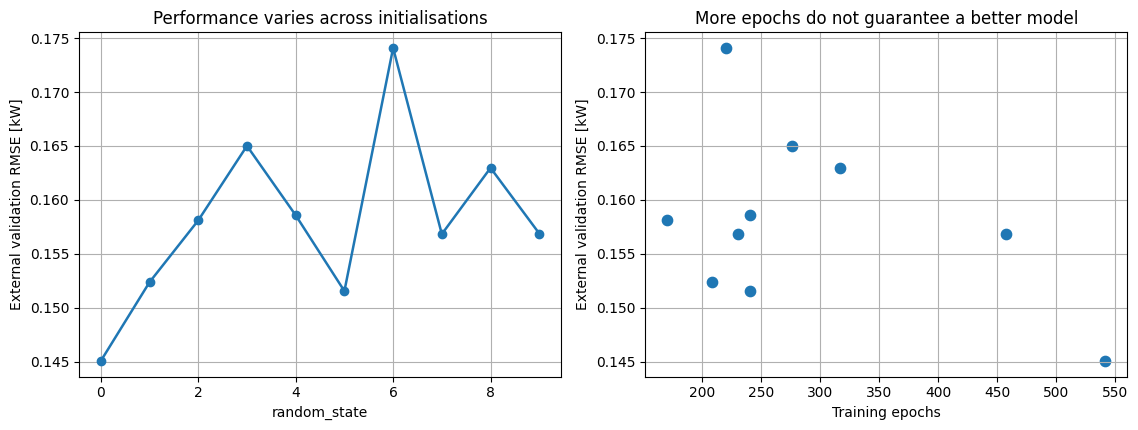

,random_state,validation_RMSE_kW,iterations
0,0,0.1451,542
1,1,0.1524,208
2,2,0.1581,170
3,3,0.1650,276
4,4,0.1586,240
5,5,0.1515,240
6,6,0.1741,220
7,7,0.1568,458
8,8,0.1630,317
9,9,0.1569,230


In [ ]:
seed_rows = []
for seed in range(10):
    model = make_pipeline(StandardScaler(), make_mlp(random_state=seed))
    model.fit(X_train, y_train)
    seed_rows.append({
        "random_state": seed,
        "validation_RMSE_kW": rmse(y_validation, model.predict(X_validation)),
        "iterations": model.named_steps["mlpregressor"].n_iter_,
    })
seed_results = pd.DataFrame(seed_rows)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
axes[0].plot(seed_results.random_state, seed_results.validation_RMSE_kW,
             marker="o", linewidth=1.8)
axes[0].set(xlabel="random_state", ylabel="External validation RMSE [kW]",
            title="Performance varies across initialisations")
axes[1].scatter(seed_results.iterations, seed_results.validation_RMSE_kW, s=55)
axes[1].set(xlabel="Training epochs", ylabel="External validation RMSE [kW]",
            title="More epochs do not guarantee a better model")
for ax in axes: ax.grid(True)
fig.tight_layout(); plt.show()
seed_results


## 📂 5.4.12 L2 regularisation with `alpha`

`alpha` penalises large weights. Very weak regularisation can allow unnecessary
flexibility; very strong regularisation can underfit. Its useful value depends on data,
scaling, architecture and solver choices.


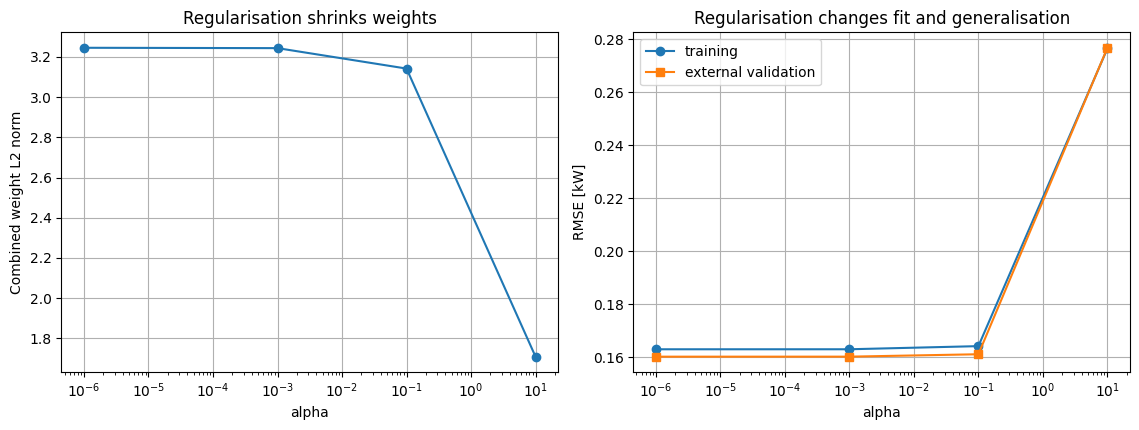

,alpha,weight_L2_norm,training_RMSE_kW,validation_RMSE_kW
0,1.0000e-06,3.2453,0.1630,0.1602
1,1.0000e-03,3.2435,0.1630,0.1603
2,1.0000e-01,3.1418,0.1642,0.1612
3,1.0000e+01,1.7088,0.2766,0.2768


In [ ]:
alpha_rows = []
for alpha in [1e-6, 1e-3, 1e-1, 10.0]:
    model = make_pipeline(StandardScaler(), make_mlp(alpha=alpha, random_state=42))
    model.fit(X_train, y_train)
    fitted = model.named_steps["mlpregressor"]
    weight_norm = np.sqrt(sum(np.sum(w**2) for w in fitted.coefs_))
    alpha_rows.append({
        "alpha": alpha,
        "weight_L2_norm": weight_norm,
        "training_RMSE_kW": rmse(y_train, model.predict(X_train)),
        "validation_RMSE_kW": rmse(y_validation, model.predict(X_validation)),
    })
alpha_results = pd.DataFrame(alpha_rows)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
axes[0].semilogx(alpha_results.alpha, alpha_results.weight_L2_norm, marker="o")
axes[0].set(xlabel="alpha", ylabel="Combined weight L2 norm",
            title="Regularisation shrinks weights")
axes[1].semilogx(alpha_results.alpha, alpha_results.training_RMSE_kW,
                 marker="o", label="training")
axes[1].semilogx(alpha_results.alpha, alpha_results.validation_RMSE_kW,
                 marker="s", label="external validation")
axes[1].set(xlabel="alpha", ylabel="RMSE [kW]",
            title="Regularisation changes fit and generalisation")
for ax in axes: ax.grid(True)
axes[1].legend(); fig.tight_layout(); plt.show()
alpha_results


## 📂 5.4.13 Extrapolation and physical constraints

A regression MLP has no built-in knowledge that power must be non-negative, that the
inverter has a maximum rating, or that the PVWatts relationship should continue in a
particular way. Smooth in-range performance does not license extrapolation.


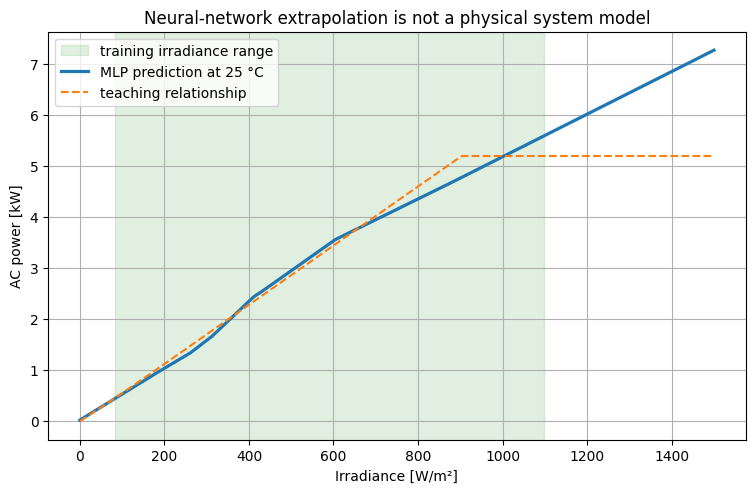

In [ ]:
extended_irradiance = np.linspace(0, 1500, 500)
slice_temperature = 25.0
extended_queries = pd.DataFrame({
    "irradiance_wm2": extended_irradiance,
    "cell_temperature_c": slice_temperature,
})
ideal_slice = (extended_irradiance / 1000) * rated_dc_kw
truth_slice = np.clip(0.96 * ideal_slice *
                      (1 - 0.08 * np.exp(-extended_irradiance / 180)), 0, 5.2)

fig, ax = plt.subplots(figsize=(9, 5.3))
ax.axvspan(X_train.irradiance_wm2.min(), X_train.irradiance_wm2.max(),
           color="green", alpha=0.12, label="training irradiance range")
ax.plot(extended_irradiance, selected_mlp.predict(extended_queries), linewidth=2.3,
        label="MLP prediction at 25 °C")
ax.plot(extended_irradiance, truth_slice, "--", label="teaching relationship")
ax.set(xlabel="Irradiance [W/m²]", ylabel="AC power [kW]",
       title="Neural-network extrapolation is not a physical system model")
ax.grid(True); ax.legend(); plt.show()


In [ ]:
def predict_with_box_check(model, query, training_features):
    result = query.copy()
    result["predicted_power_kw"] = model.predict(query)
    result["inside_training_box"] = (
        query.ge(training_features.min()).all(axis=1)
        & query.le(training_features.max()).all(axis=1)
    )
    return result

engineering_queries = pd.DataFrame({
    "irradiance_wm2": [500.0, 1000.0, 1250.0, 600.0],
    "cell_temperature_c": [30.0, 60.0, 35.0, 90.0],
})
predict_with_box_check(selected_mlp, engineering_queries, X_train)


,irradiance_wm2,cell_temperature_c,predicted_power_kw,inside_training_box
0,500.0,30.0,2.9426,True
1,1000.0,60.0,4.9432,True
2,1250.0,35.0,6.1639,False
3,600.0,90.0,2.5293,False


### ⚠️ Range checks are only a first defence

A query inside the rectangular feature ranges may still be far from observed feature
combinations. Output clipping can enforce a numerical bound but does not repair an
unsupported model or prove physical validity.


## 📂 5.4.14 Method limitations and engineering checks

Before using a neural-network regressor, ask:

1. Does the task require flexibility beyond a simpler baseline?
2. Were features scaled using training data only?
3. Is architecture small enough for the data and task?
4. Were convergence and external validation both checked?
5. Was sensitivity to random initialisation assessed?
6. Was regularisation selected using validation evidence?
7. Are predictions acceptable across important operating regions, not just on average?
8. Are queries supported by relevant training combinations?
9. Are physical limits checked independently?
10. Are reproducibility settings, data provenance and limitations documented?

scikit-learn's MLP has no GPU support and is not intended as a large-scale deep-learning
framework. For small engineering regression tasks, that simplicity can be an advantage.


## 📂 5.4.15 Useful packages, parameters and attributes

| Item | Purpose | Important caution |
|---|---|---|
| `MLPRegressor` | Fit a multilayer perceptron | Flexible and sensitive to choices |
| `hidden_layer_sizes` | Set neurons in each hidden layer | More capacity is not always better |
| `activation` | Add hidden-layer nonlinearity | Regression output remains unbounded by default |
| `solver` | Choose optimisation algorithm | Solver suitability depends on data size |
| `alpha` | Apply L2 weight regularisation | Must be selected with validation evidence |
| `learning_rate_init` | Set initial Adam/SGD step size | Too large may destabilise; too small may be slow |
| `early_stopping` | Monitor an internal training fraction | Does not replace external validation |
| `random_state` | Reproduce initialisation and shuffling | One seed does not establish stability |
| `loss_curve_` | Inspect training objective by epoch | Falling loss does not prove generalisation |
| `validation_scores_` | Inspect internal early-stopping R² | Available when early stopping is enabled |
| `coefs_`, `intercepts_` | Inspect learned parameter arrays | Individual weights are rarely interpretable alone |
| `n_iter_` | Report completed epochs | More epochs are not automatically better |


## 📂 5.4.16 Engineering workflow and summary

A defensible neural-regression workflow is to define the task and domain; reserve
external validation data; establish a simple baseline; scale features inside a pipeline;
start with a small network; monitor optimisation and validation; investigate architecture,
regularisation and multiple seeds; inspect response surfaces and operating regions; flag
unsupported queries; and report assumptions, provenance and reproducibility choices.

Neural networks can learn complex nonlinear interactions, but their flexibility makes
validation, diagnostics and engineering constraints more important—not less.


## 📚 References

* scikit-learn developers, *MLPRegressor*, stable documentation.
* scikit-learn developers, *Neural Network Models (Supervised)*, stable documentation.
* scikit-learn developers, *StandardScaler*, stable documentation.
* National Renewable Energy Laboratory, *PVWatts Version 5 Manual*.

## 🤖 AI Acknowledgment

Generative AI was used to help structure explanations, develop teaching examples and
review code. The teaching team remains responsible for the mathematical content,
engineering interpretation, source selection and final notebook.
